# 4. Статистический анализ цен

**Вопрос:** существует ли систематическое различие цен в выборке сопоставленных товаров?

Наблюдательное исследование двух онлайн-каталогов на одну дату. Единица наблюдения — товарная пара,
а не покупатель, заказ или магазин. Это не A/B-тест и не оценка причинного эффекта.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Работает при запуске Jupyter из корня проекта и из папки notebooks.
ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'processed').is_dir():
    raise FileNotFoundError('Открой Jupyter из корня проекта.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from scripts.analyze_prices import load_pairs, main as run_analysis
pairs = load_pairs()
print('Пар:', len(pairs))
pairs[['product_name_sk', 'product_name_am', 'sk_effective_price_eur', 'am_effective_price_eur']].head(6)

Пар: 841


,product_name_sk,product_name_am,sk_effective_price_eur,am_effective_price_eur
0,KALAMATA PAPADIMITRIOU Balsamic Cream With Pom...,Kalamata Papadimitriou Balsamic Cream with Pom...,3.18,3.19
1,SAILOR Table Salt 250 g 140072,Sailor Table Salt 250 g,0.53,0.55
2,ALAMBRA Natural Pomegranate Juice 330ml 713366,Alambra Natural Pomegranate Juice 330 ml,1.05,1.15
3,GRIGORIOU Pizza Margarita 430g 498875,Grigoriou Pizza Margarita 430 g,3.75,3.79
4,GRIGORIOU Pizza Special 490g 498877,Grigoriou Pizza Special 490 g,4.35,4.59
5,KYKKOS Natural Mineral Water 6x1.5lt 134615,Kykkos Natural Mineral Water 6x1.5 L,2.25,2.45


## Метрика

Цена — акционная, если указана, иначе обычная. Сравнивается цена упаковки/товарной позиции.
Отдельные цены за кг/л в рабочем датасете рассчитывались, но основным тестом не использовались.

```text
ratio_i = price_AM_i / price_SK_i
log_ratio_i = ln(ratio_i)
геометрическое отношение = exp(mean(log_ratio_i))
эффект, % = (геометрическое отношение − 1) × 100
```

Обычное среднее процентных различий считается иначе. Оно равно 3,20%,
геометрический эффект — 2,17%, медиана — 1,34%. Каждый товар имеет одинаковый вес.

## Размер выборки и чувствительность теста

Как в исходном исследовании, оцениваем минимально обнаружимый эффект при 841 паре, alpha = 0,05 и мощности 80%/90%. Это расчёт чувствительности t-теста на основе наблюдаемого разброса, а не проверка репрезентативности.

In [3]:
from statsmodels.stats.power import TTestPower
import numpy as np

power = TTestPower()
mde = []
for target_power in [.8, .9]:
    standardized = power.solve_power(nobs=len(pairs), power=target_power, alpha=.05, alternative='two-sided')
    mde.append({'мощность': target_power,
                'минимально обнаружимый геометрический эффект, %':
                np.expm1(standardized * pairs['log_ratio'].std(ddof=1)) * 100})
pd.DataFrame(mde)

,мощность,"минимально обнаружимый геометрический эффект, %"
0,0.8,1.443111
1,0.9,1.671619


## Проверки и доверительные интервалы

Основной тест — двусторонний one-sample t-test логарифмов отношений против нуля;
это эквивалент парного t-test логарифмов цен. H0: средний log_ratio равен нулю.
Дополнительно — Wilcoxon signed-rank, sign test и парный bootstrap
(10 000 выборок с возвращением, seed = 13).

In [4]:
metrics = run_analysis()
pd.DataFrame({
    'показатель': ['геометрическое отношение цен', 'геометрический эффект, %',
                  'обычное среднее различий, %', 'медиана различий, %', 'p-value t-test'],
    'значение': [metrics['geometric_mean_price_ratio'], metrics['geometric_price_gap_percent'],
                metrics['arithmetic_mean_item_gap_percent'], metrics['median_item_gap_percent'], metrics['t_pvalue']]
})

{
  "n_pairs": 841,
  "geometric_mean_price_ratio": 1.0216599705808764,
  "geometric_price_gap_percent": 2.1659970580876364,
  "arithmetic_mean_item_gap_percent": 3.2035362849065216,
  "median_item_gap_percent": 1.3432835820895495,
  "mean_difference_eur": 0.04813317479191441,
  "t_statistic": 4.194792157166233,
  "t_pvalue": 3.0216273632857814e-05,
  "t_ci95_percent": [
    1.1467226063871636,
    3.1955429291788517
  ],
  "wilcoxon_statistic": 97009.0,
  "wilcoxon_pvalue": 1.733275821439612e-14,
  "sign_test_pvalue": 2.151324199037356e-23,
  "alphamega_more_expensive": 514,
  "sklavenitis_more_expensive": 242,
  "same_price": 85,
  "bootstrap_iterations": 10000,
  "bootstrap_seed": 13,
  "bootstrap_ci95_percent": [
    1.127608476136141,
    3.160068836903436
  ],
  "exact_nonempty_size_pairs": 818,
  "same_size_flag_pairs": 820,
  "sklavenitis_products": 3342,
  "sklavenitis_coverage_percent": 25.164572112507482,
  "alphamega_products": 8672,
  "alphamega_coverage_percent": 9.697878

,показатель,значение
0,геометрическое отношение цен,1.021660
1,"геометрический эффект, %",2.165997
2,"обычное среднее различий, %",3.203536
3,"медиана различий, %",1.343284
4,p-value t-test,0.000030


In [5]:
print('95% bootstrap CI, %:', metrics['bootstrap_ci95_percent'])
print('95% t-интервал, %:', metrics['t_ci95_percent'])
pd.read_csv(ROOT / 'reports/tables/statistical_tests.csv')

95% bootstrap CI, %: [1.127608476136141, 3.160068836903436]
95% t-интервал, %: [1.1467226063871636, 3.1955429291788517]


,test,pvalue
0,t-test on paired log prices,3.021627e-05
1,Wilcoxon signed-rank,1.733276e-14
2,Sign test,2.151324e-23


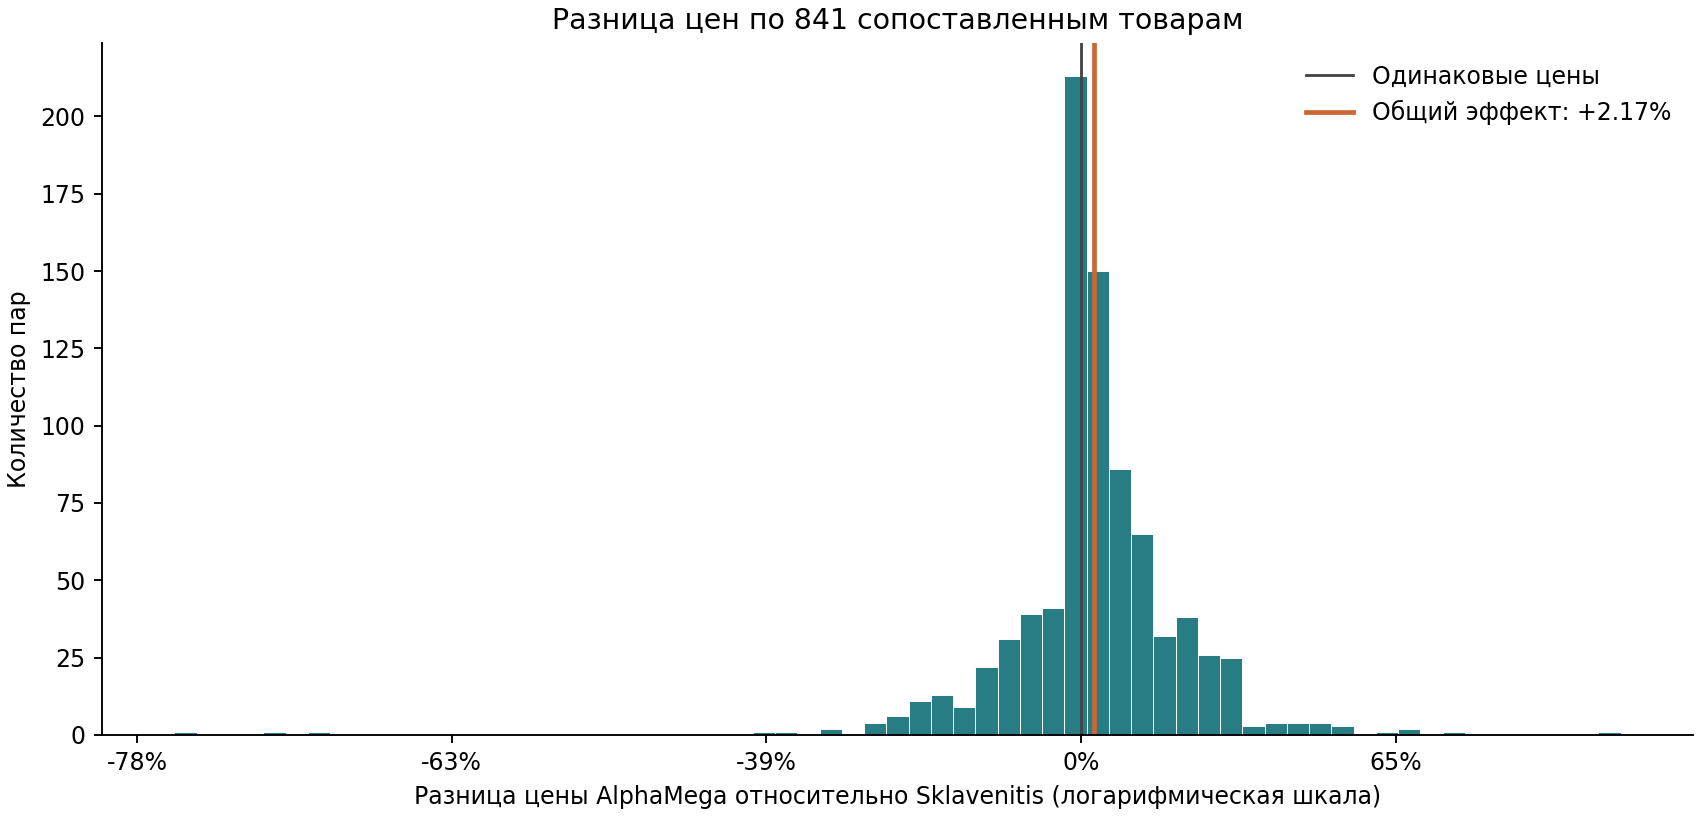

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/figures/price_gap_distribution.png')))

## Фасовки и ручная проверка

У 818 пар заполненные извлечённые фасовки совпадают. У ещё двух пар оба значения пустые,
поэтому автоматический флаг также равен True. 21 пару с расхождениями автор проверила вручную
и признала сопоставимой по карточкам: небольшие отличия, пропуски или возможные ошибки названий.
Это не означает, что числовое равенство фасовок гарантировано у каждой пары.

Если различие объёма реально, цена упаковки включает его влияние. В дополнительной проверке
только 818 пар с заполненной совпадающей фасовкой эффект остаётся положительным и значимым.
Это проверка устойчивости, а не отмена ручных решений автора.

In [7]:
pd.Series(metrics['exact_size_sensitivity'], name='Проверка устойчивости')

n_pairs                                                             818
geometric_price_gap_percent                                    1.895488
t_pvalue                                                       0.000189
t_ci95_percent                 [0.8989331796192965, 2.9018848289186114]
Name: Проверка устойчивости, dtype: object

## Анализ по категориям

Берём первый уровень категории Sklavenitis. На график включаем категории с ≥20 парами.
Это описательный анализ: отдельные проверки гипотез и поправки на множественные сравнения не выполняются.

In [8]:
pd.read_csv(ROOT / 'reports/tables/category_price_comparison.csv').head(12)

,main_category,n_pairs,mean_log_ratio,arithmetic_gap_percent,median_gap_percent,mean_difference_eur,alphamega_more_expensive,same_price,geometric_gap_percent
0,Fresh Fruits & Vegetables,14,0.227987,29.463810,19.949389,0.748571,13,1,25.606893
1,Fresh Meat -Fish & Seafood,3,0.128650,20.860173,1.785714,2.100000,2,0,13.729234
2,Baby & Children's Food,1,0.116072,12.307692,12.307692,0.240000,1,0,12.307692
3,International Cuisine,17,0.090069,10.248100,10.576923,0.244706,12,2,9.424993
4,"Soft Drinks, Water & Juices",49,0.073068,7.926048,3.913043,0.161020,39,5,7.580413
5,"Cookies, Chocolates & Sweets",47,0.072561,8.331060,6.400000,0.162128,28,5,7.525813
6,"Eggs, Butter, Fresh Doughs & Broths",11,0.058867,6.156198,6.349206,0.210909,9,2,6.063366
7,New,15,0.057045,6.206431,4.878049,0.172000,11,2,5.870378
8,Cava,72,0.044303,4.849078,2.601504,0.153750,62,5,4.529915
9,Gluten Free,15,0.033011,4.084231,1.102941,0.110667,9,4,3.356153


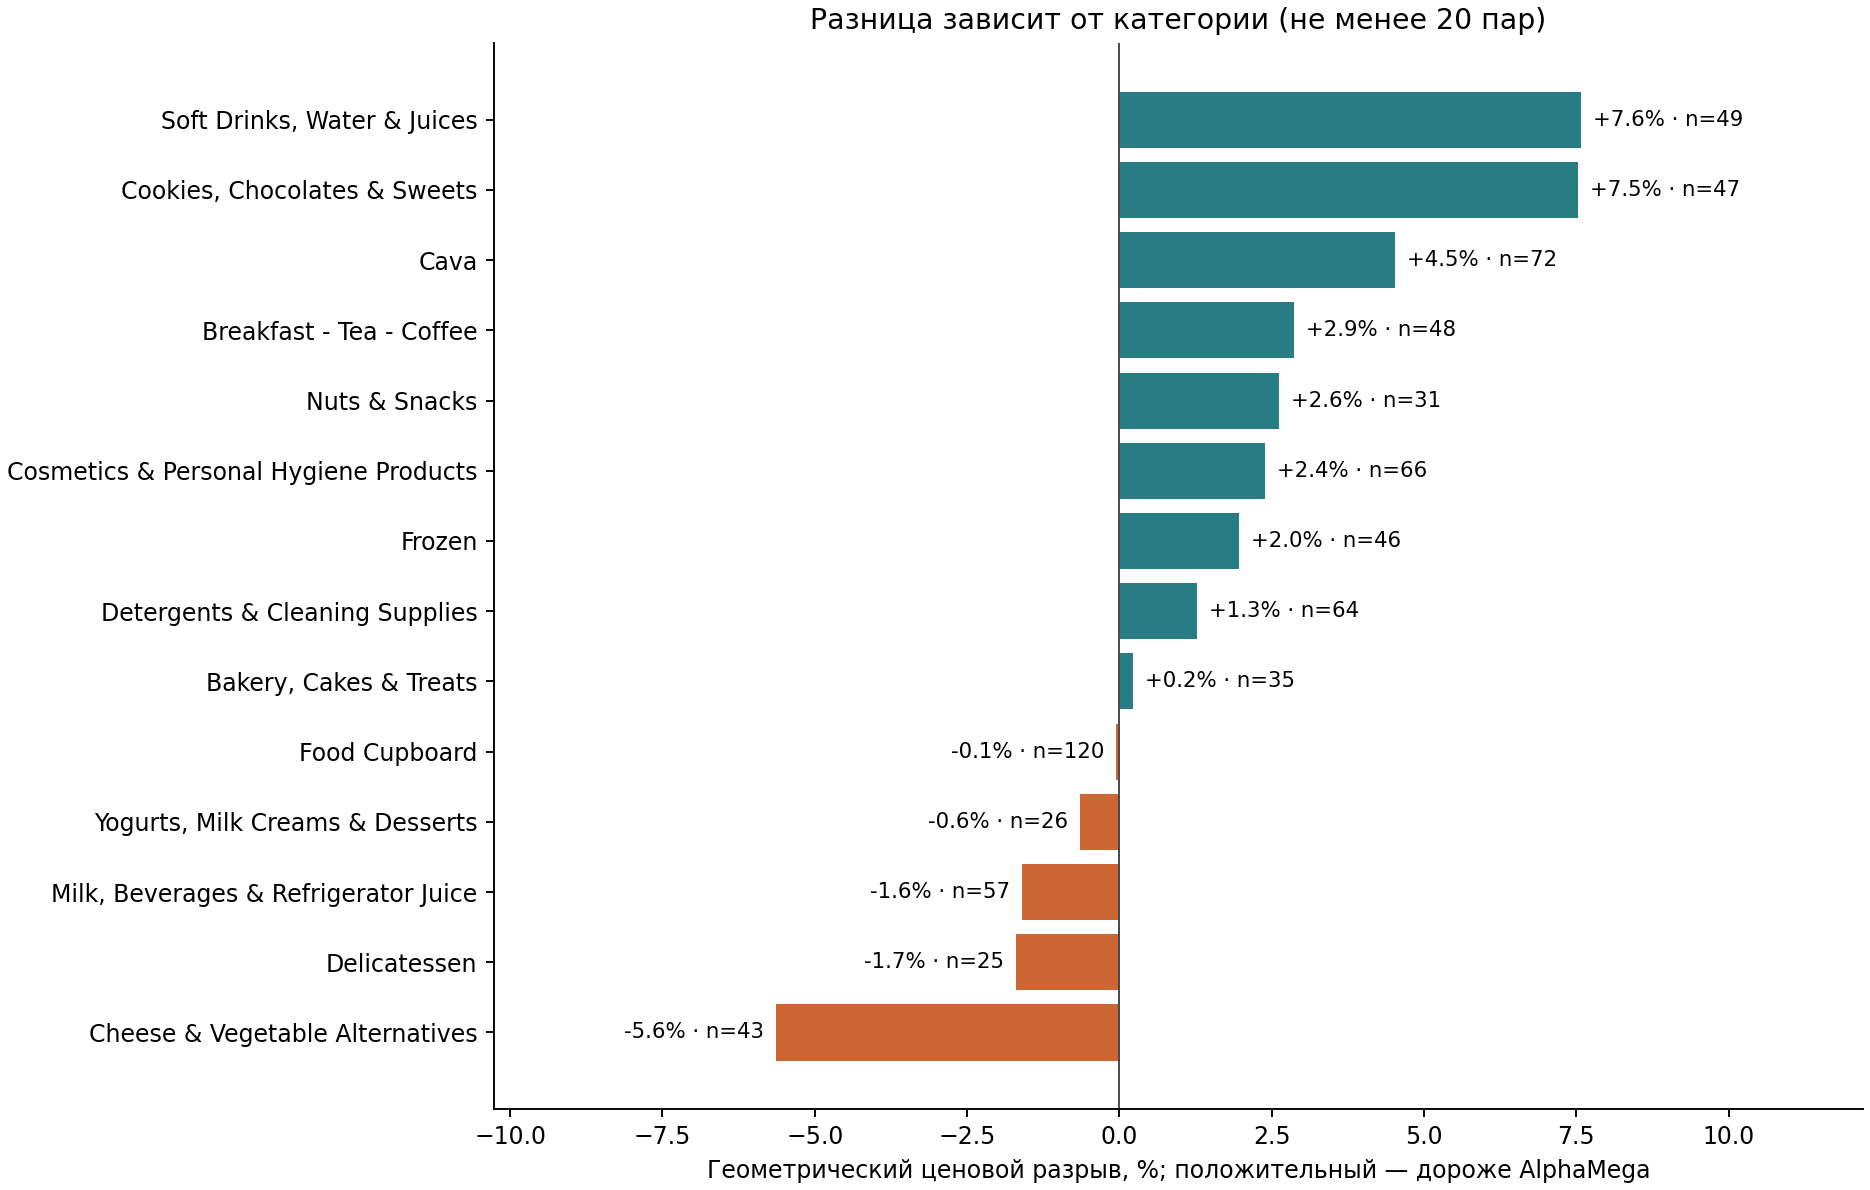

In [9]:
display(Image(filename=str(ROOT / 'reports/figures/category_price_gap.png')))

## Представительность и границы вывода

Сопоставлено 25,16% загруженных позиций Sklavenitis и 9,70% AlphaMega. Выборка не случайная:
попадают товары с общим аналогом и успешным сопоставлением. Это не доказательство
репрезентативности для всего ассортимента. Доли категорий отличаются, весов покупательской
корзины нет, наблюдение только за одну дату. Bootstrap оценивает разброс внутри данной выборки,
но не устраняет смещение отбора. Зависимость цен внутри брендов/категорий отдельно не моделировалась.

Источники различаются: Sklavenitis — Wolt, AlphaMega — сайт магазина. Возможное влияние канала
продаж, акций и ошибок карточек нельзя отделить от различий магазинов.

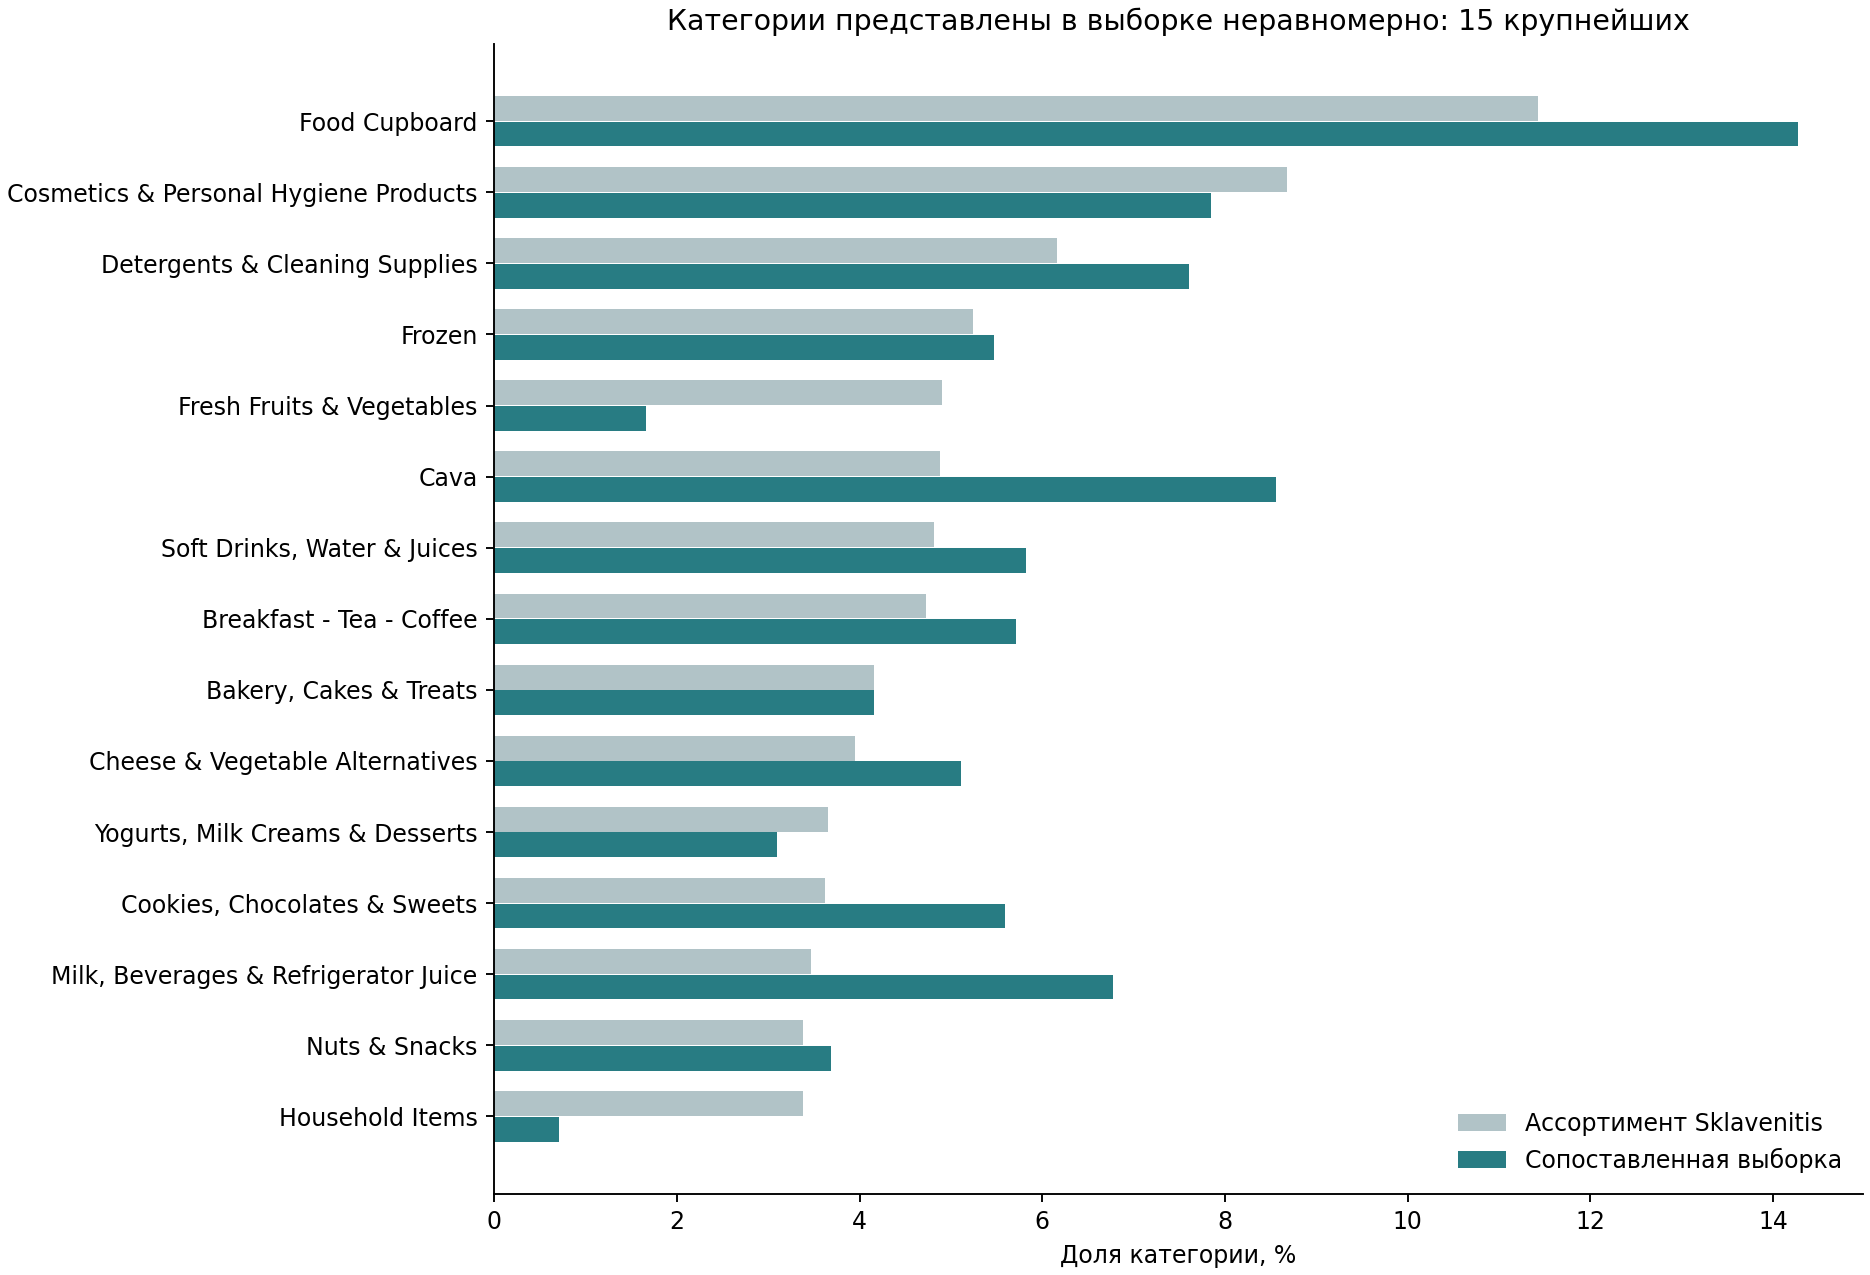

In [10]:
display(Image(filename=str(ROOT / 'reports/figures/category_coverage.png')))

## Вывод

В исследованной выборке AlphaMega имеет более высокий геометрический уровень цен:
эффект +2,17%, bootstrap 95% CI [+1,13%; +3,16%]. Это согласуется с t-test и дополнительными тестами.
Результат относится к сопоставленным товарам в выбранных онлайн-каналах на дату сбора.
Он не означает, что любая покупательская корзина или весь ассортимент AlphaMega дороже на 2,17%.